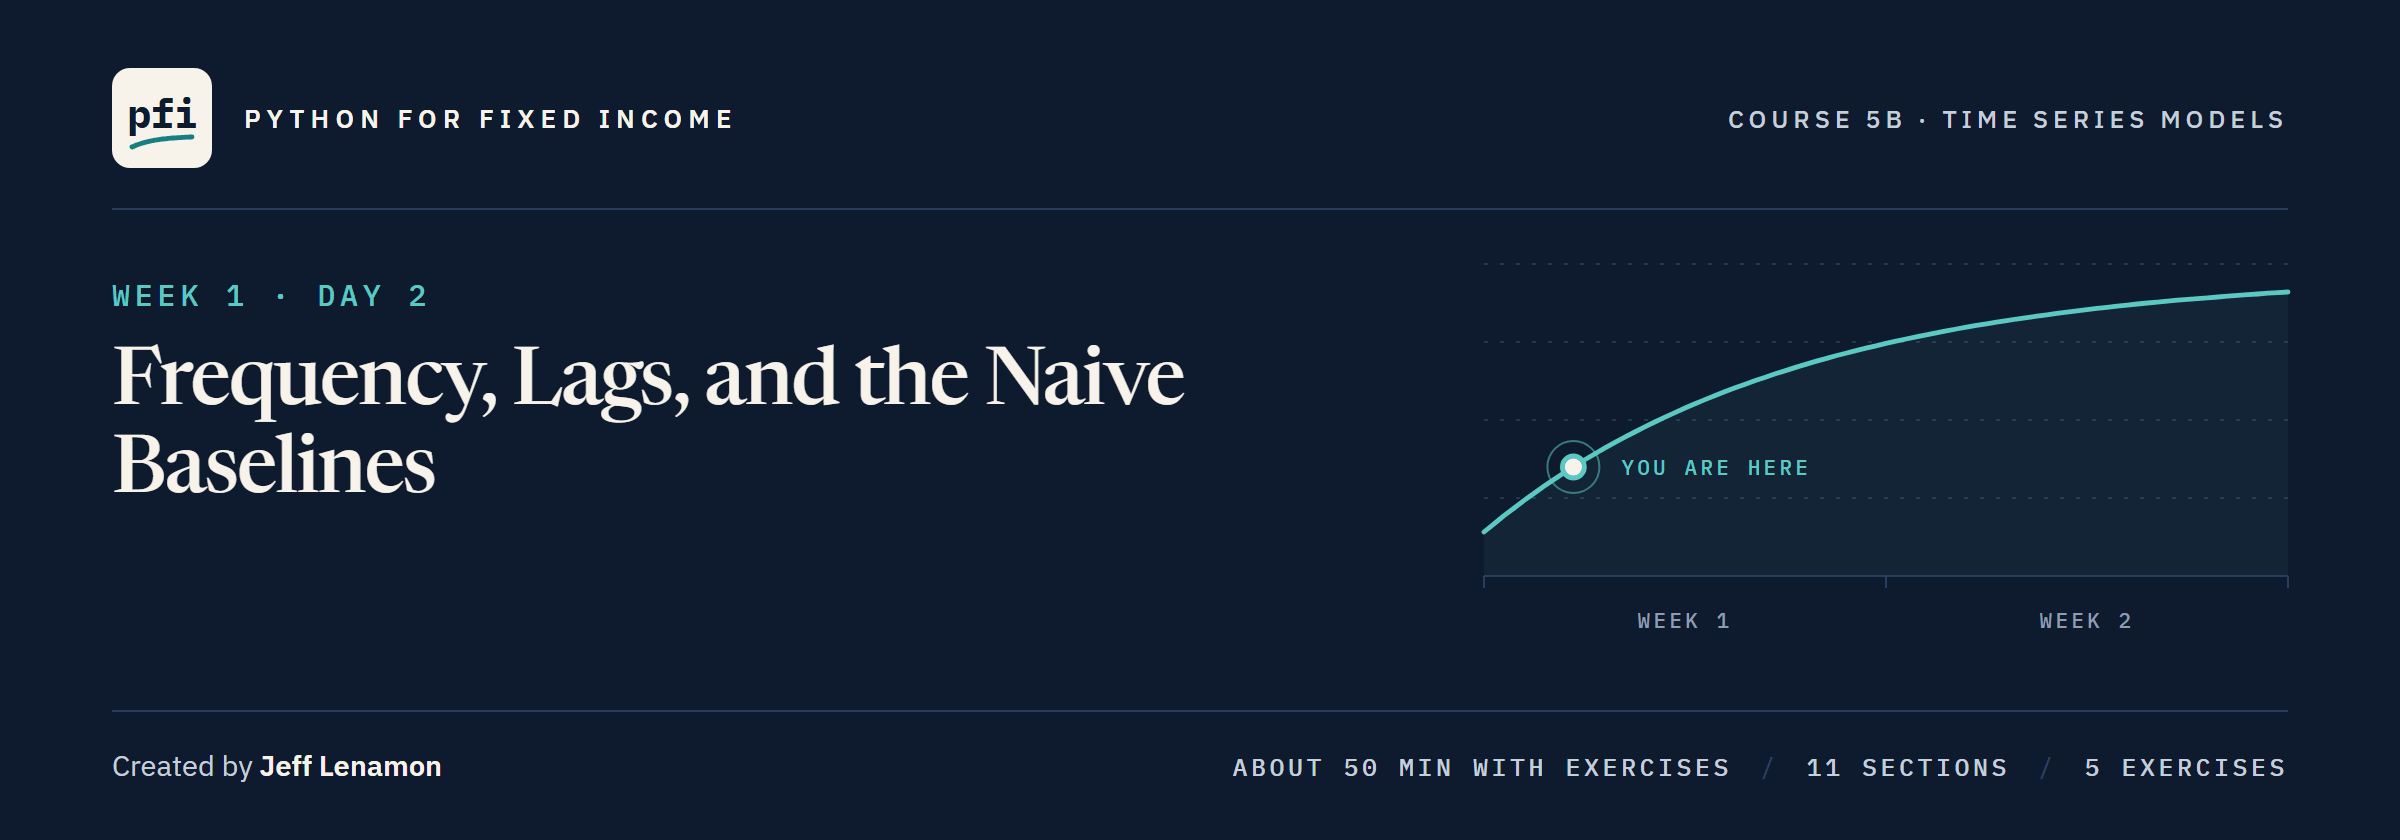

# Frequency, Lags, and the Naive Baselines

Week 1, Day 2. Set the dates every model in this course is fitted and scored on, build lags that use only earlier dates, and score three rules with no model in them, the bar every later model must clear.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week1/day2/02_frequency_lags_and_the_naive_baselines.ipynb)

# Problem Statement

## Business Context

A rates and credit desk will try nine days of time series models on five daily series: the 2 Yr and 10 Yr Treasury yields, the 2s10s slope, and an IG and an HY spread.
Before any model, it sets the bar: the score of a rule with no model in it.
Each rule gives the change in a series on a date, in bp, from the dates before it, and is scored against the change that happened.
Textbooks name these forecasting models, but in this course every output is a value for a date inside the file and never a forecast of rates or spreads.

## Objectives

Set the development and held-out years before looking at a value, build lags and changes, and prove a feature uses only earlier dates.
Build three rules with no model in them, score them with MAE, RMSE and MASE, write the walk-forward loop over five folds, and build the baseline table for five series.

## Data Dictionary

`treasury_par_yields.csv`, one row per trading day:

1. `date`: the trading day, the index
2. `2 Yr`, `10 Yr`: par yields, in percent (the other 12 tenors are not used today)

`course3_synthetic_spreads.csv`, the same dates:

3. `ig_spread_bp`, `hy_spread_bp`: synthetic IG and HY spreads, in bp

Made here, all in bp: the `2 Yr` and `10 Yr` (percent times 100), `2s10s` (10 Yr less 2 Yr, Course 3's slope), `IG` and `HY`.

## Your Route Through Day 2

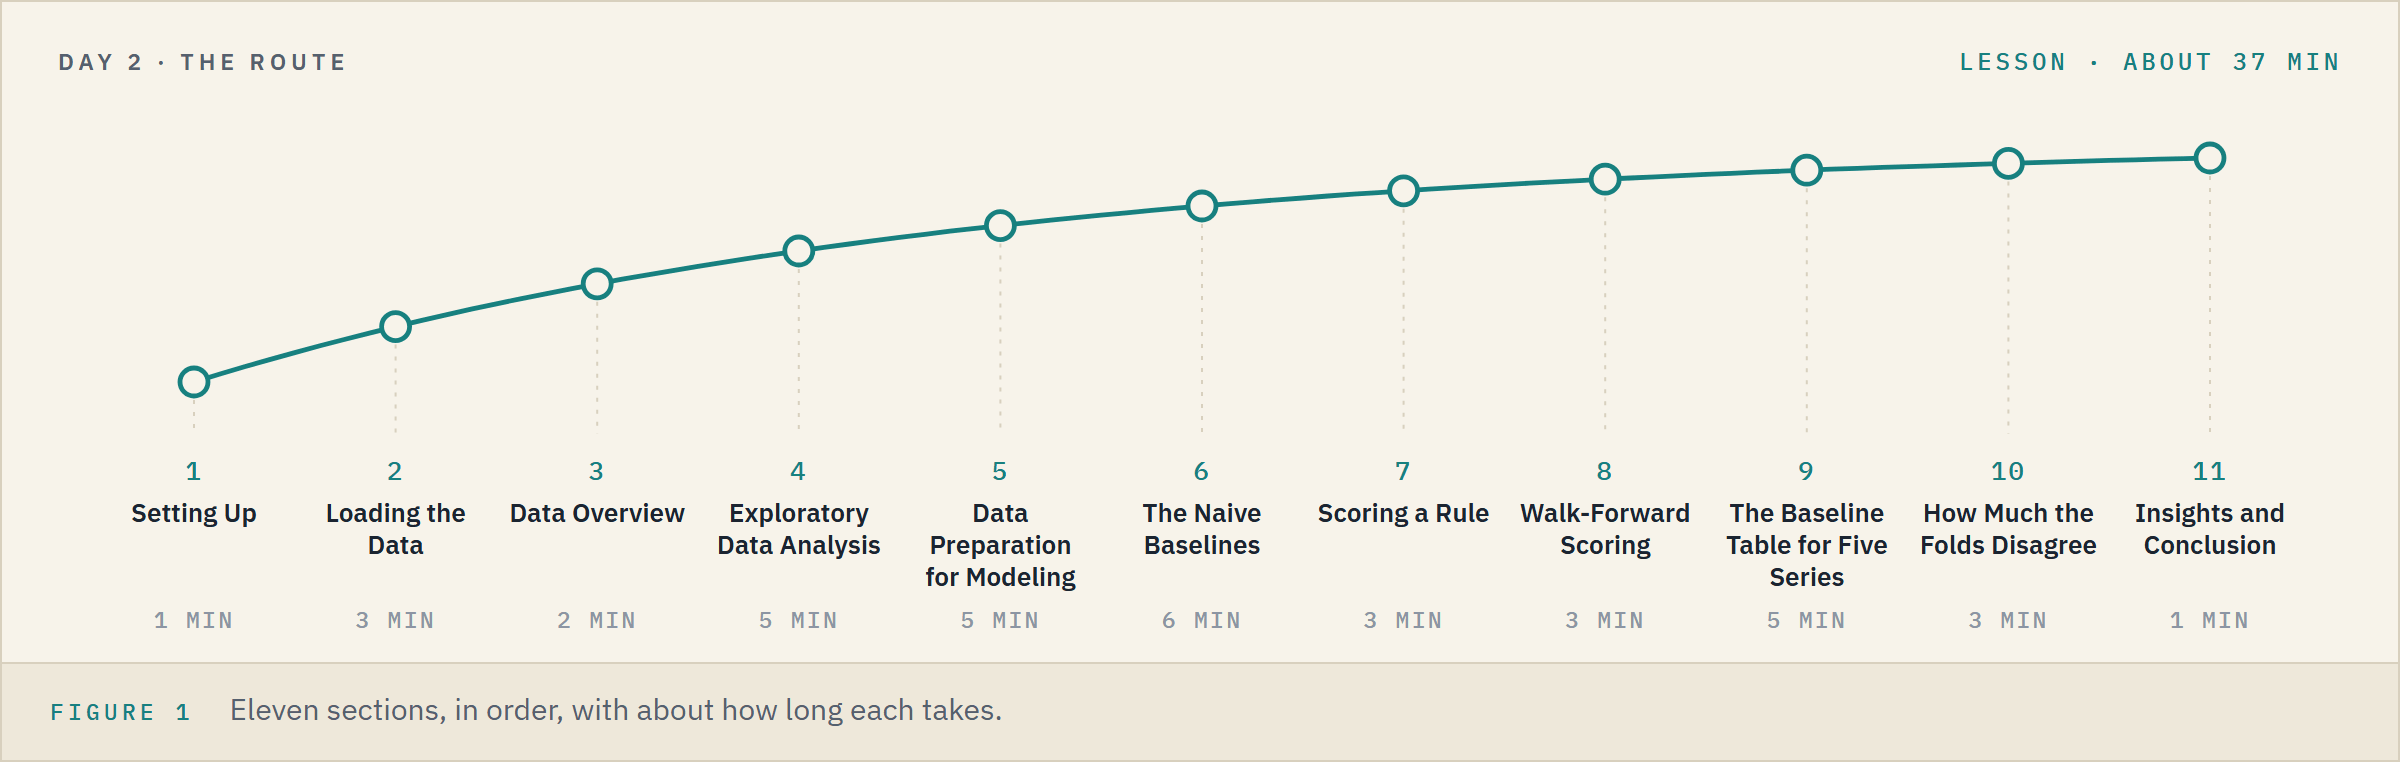

**Time.** About 37 minutes for the lesson, then about 15 for the five exercises.

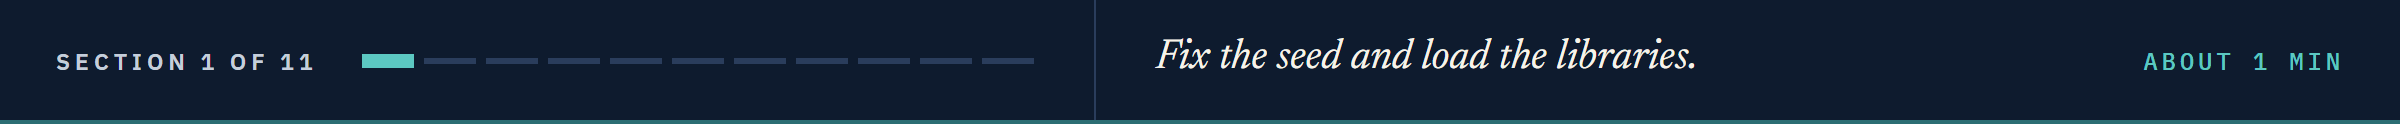

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to cut the dates into walk-forward folds, and to score a rule in bp
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

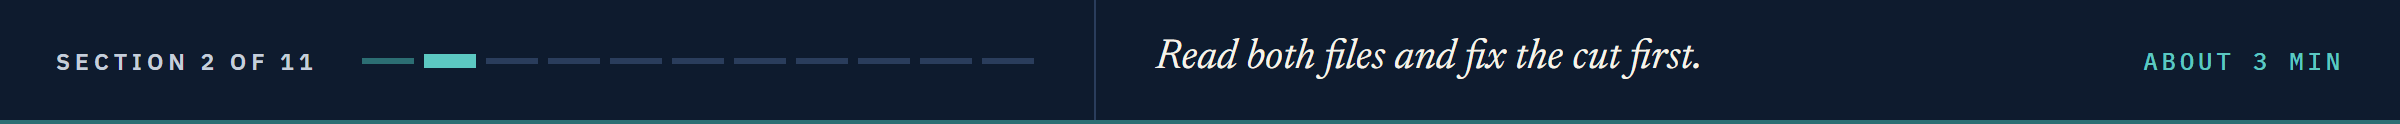

# Loading the Data

## Reading the Two Files

Q. Do the two files hold the same dates?

In [3]:
# the Treasury par yields (percent) and the synthetic spreads (bp): one row per trading day
yields = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")
spreads = pd.read_csv(DATA + "course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")

# their shapes, whether their dates match row for row, and the first and last date
print(yields.shape, spreads.shape, yields.index.equals(spreads.index))
print(yields.index[0].date(), "to", yields.index[-1].date())

(2940, 14) (2940, 2) True
2015-01-02 to 2026-10-02


2,940 trading days in each file, the same dates row for row.

## Setting the Cut Before We Look

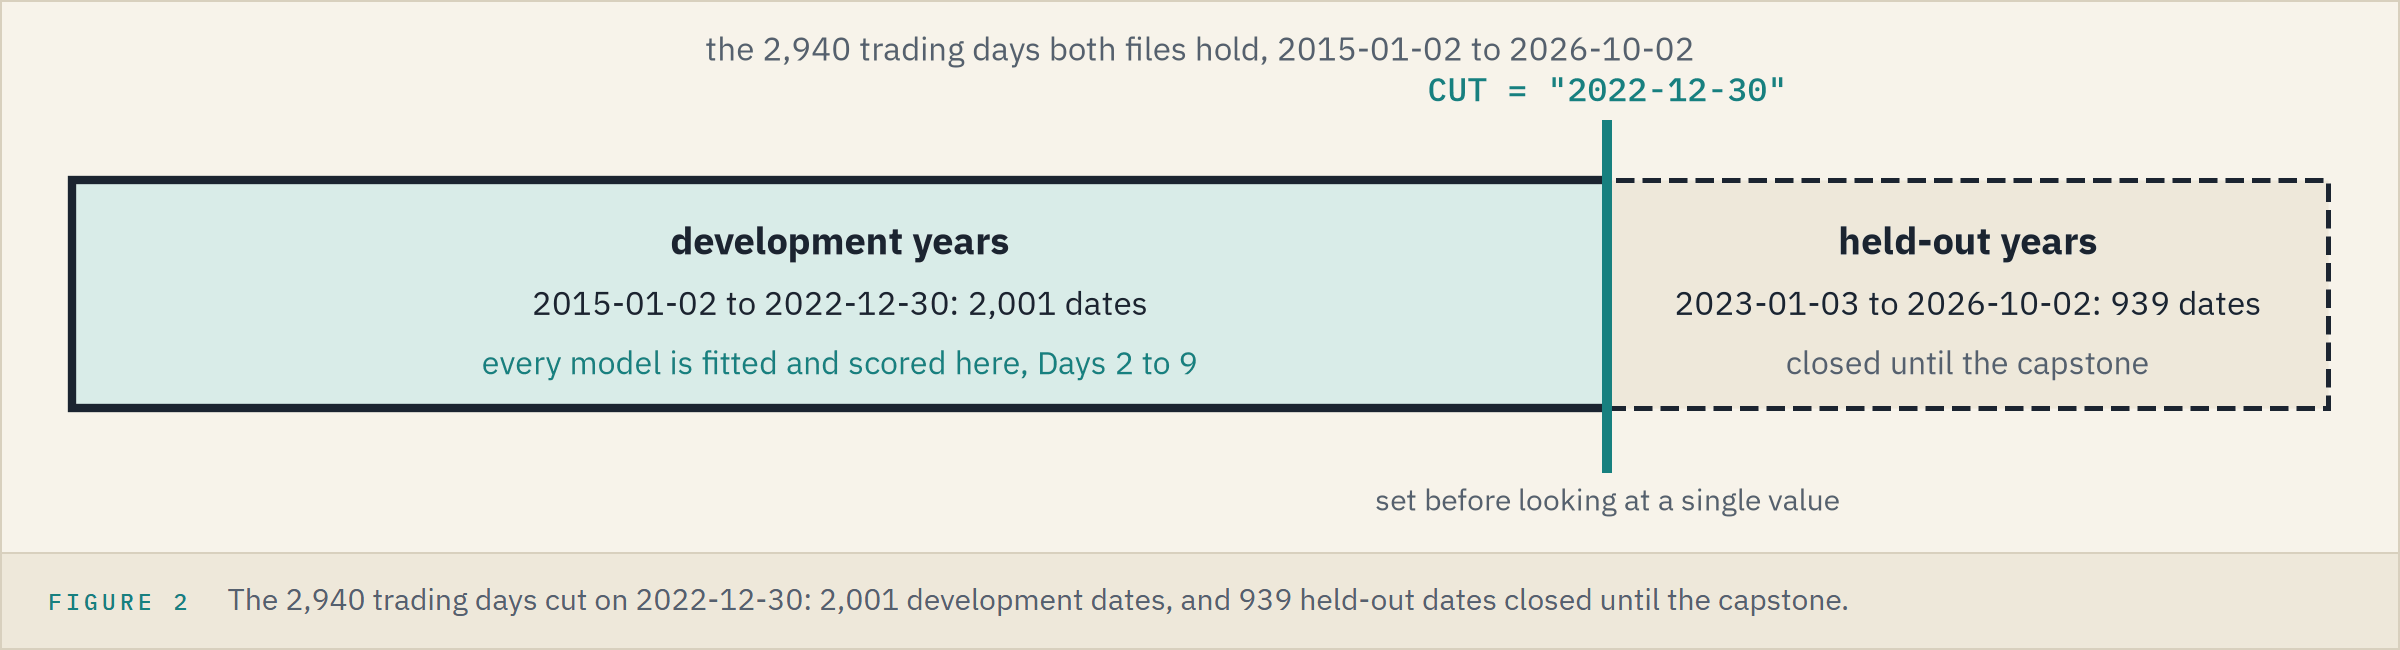

The **development years** are where every model of this course is fitted and scored, Days 2 to 9.
The **held-out years** stay closed until the capstone, which opens them once for the models chosen here.
We set the cut now, before looking at a single value, so nothing we see can move it.

In [4]:
# the last development date: every model is fitted and scored on the dates up to it
CUT = "2022-12-30"
development = yields.loc[:CUT]

# the held-out dates are only counted, never read
held_out = yields.index[yields.index > CUT]
print("Development:", len(development), "dates,", development.index[0].date(), "to", development.index[-1].date())
print("Held out:", len(held_out), "dates,", held_out[0].date(), "to", held_out[-1].date())

Development: 2001 dates, 2015-01-02 to 2022-12-30
Held out: 939 dates, 2023-01-03 to 2026-10-02


## Five Series in bp

In [5]:
# the five series in bp: yields in percent times 100, Course 3's 2s10s slope, the spreads as stored
# round(2) clears the binary tail a percent times 100 can leave (Course 3)
levels = pd.DataFrame({"2 Yr": (development["2 Yr"] * 100).round(2),
                       "10 Yr": (development["10 Yr"] * 100).round(2),
                       "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
                       "IG": spreads.loc[:CUT, "ig_spread_bp"],
                       "HY": spreads.loc[:CUT, "hy_spread_bp"]})
levels.head()

,2 Yr,10 Yr,2s10s,IG,HY
date,,,,,
2015-01-02,66.0000,212.0000,146.0000,90.3000,253.0000
2015-01-05,68.0000,204.0000,136.0000,89.8000,251.0000
2015-01-06,65.0000,197.0000,132.0000,90.7000,251.3000
2015-01-07,62.0000,196.0000,134.0000,90.4000,252.6000
2015-01-08,62.0000,203.0000,141.0000,90.7000,251.0000


**We fix the cut before looking at a single value; the held-out years stay closed until the capstone.**

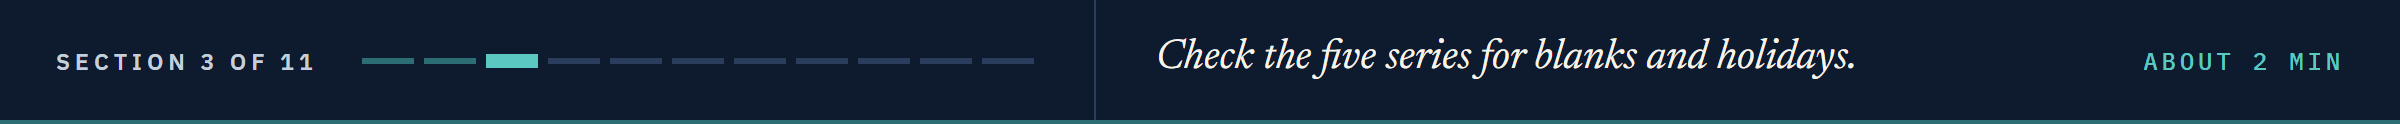

# Data Overview

## Checking the Statistical Summary

In [6]:
levels.describe()

,2 Yr,10 Yr,2s10s,IG,HY
count,2001.0000,2001.0000,2001.0000,2001.0000,2001.0000
mean,137.9265,207.8826,69.9560,87.1356,240.5106
std,106.0845,73.8736,53.4732,8.9974,33.1905
min,9.0000,52.0000,-84.0000,64.7000,157.5000
25%,60.0000,160.0000,26.0000,81.3000,215.6000
50%,121.0000,212.0000,75.0000,86.4000,240.4000
75%,221.0000,254.0000,112.0000,91.8000,262.1000
max,472.0000,425.0000,177.0000,125.9000,359.1000


The 10 Yr ran from 52 to 425 bp over the development years, the 2 Yr from 9 to 472.

The 2s10s slope ranged from 177 bp down to -84, below zero where the 2 Yr sat above the 10 Yr.

The synthetic spreads stay in narrower bands: IG 65 to 126 bp, HY 158 to 359.

## Checking for Missing Values

In [7]:
# blank cells in the five series
print("Blank cells:", levels.isna().sum().sum())

Blank cells: 0


## Checking the Frequency

A date index can carry a **frequency**, the rule that gives its next date, and `.freq` reads it.

Q. Is every weekday in the file?

In [8]:
# the index's frequency, then every weekday from the first date to the last (Course 3's bdate_range)
print("Frequency:", levels.index.freq)
weekdays = pd.bdate_range(levels.index[0], levels.index[-1])
absent = weekdays[~weekdays.isin(levels.index)]
print(len(weekdays), "weekdays,", len(absent), "with no row,", (absent.dayofweek == 0).sum(), "of them Mondays")

Frequency: None
2086 weekdays, 85 with no row, 51 of them Mondays


No frequency: trading days follow no fixed rule.

85 of the 2,086 weekdays have no row, 51 of them Mondays: the market holidays Day 1 sorted out.

**Five complete series on 2,001 trading days; a weekday with no row is a holiday, not a gap.**

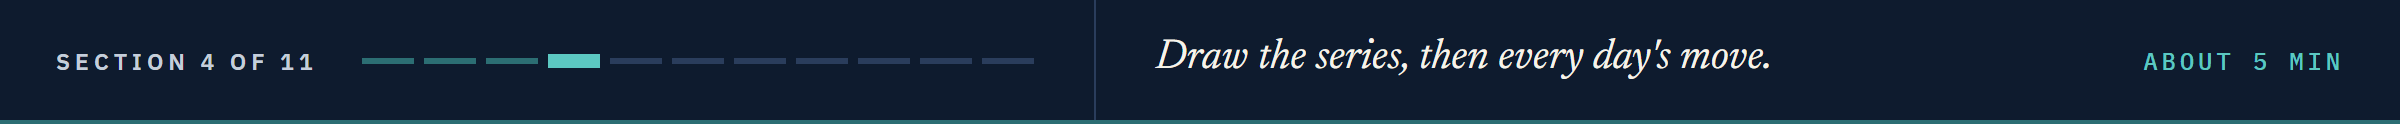

# Exploratory Data Analysis

## The Five Series at a Glance

A **change** is a level less the level on the row before, in bp (Course 3), and `diff()` makes it.

In [9]:
# each series' daily change in bp; the first date has no row before it, so it has none
changes = levels.diff().dropna()
print(changes.shape, "from", changes.index[0].date())

(2000, 5) from 2015-01-05


A **sparkline** is a small line chart with no scale, read like a word in a table.

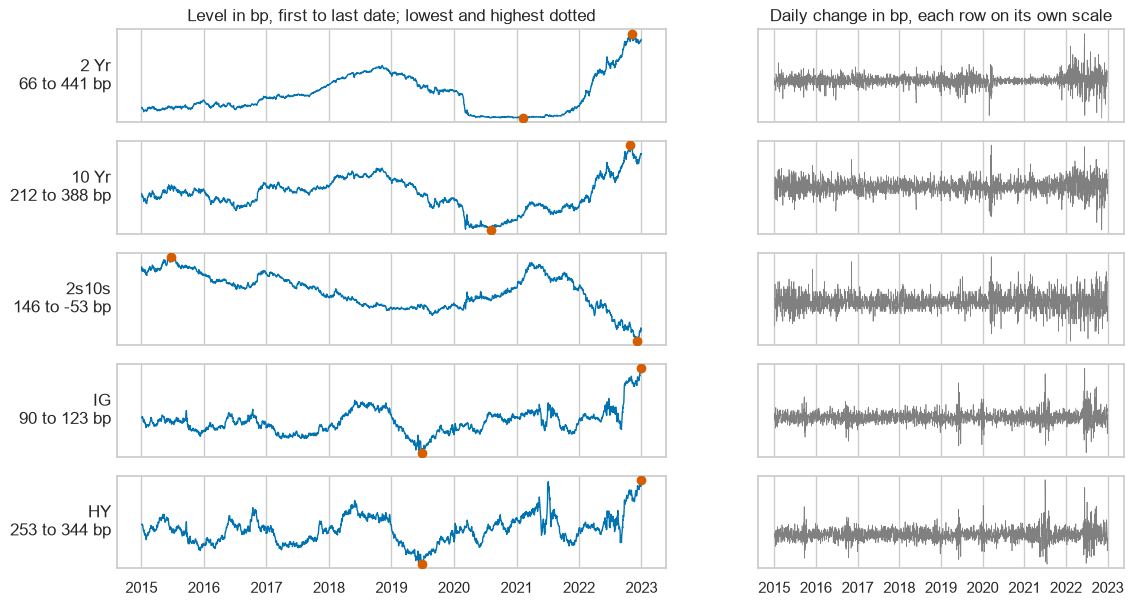

In [10]:
# one row per series: the level, its lowest and highest dotted, and the daily change, as sparklines
fig, axes = plt.subplots(5, 2, figsize=(13, 7), width_ratios=[3, 2], sharex=True)
for row, name in enumerate(levels.columns):
    level = levels[name]
    axes[row, 0].plot(level, linewidth=1)
    axes[row, 0].scatter([level.idxmin(), level.idxmax()], [level.min(), level.max()], color="C3", zorder=3)
    axes[row, 0].set_ylabel(f"{name}\n{level.iloc[0]:.0f} to {level.iloc[-1]:.0f} bp", rotation=0, ha="right", va="center")
    axes[row, 1].plot(changes[name], linewidth=0.5, color="gray")
for ax in axes.flat:
    ax.set_yticks([])
axes[0, 0].set_title("Level in bp, first to last date; lowest and highest dotted")
axes[0, 1].set_title("Daily change in bp, each row on its own scale")
plt.show()

The 10 Yr opens at 212 bp and closes at 388; the 2s10s slope opens at 146 and closes at -53.

Every level wanders far from where it started.

Every change hovers around zero, in bursts that come and go.

## The Size of Each Day's Move

A **calendar heatmap** gives each weekday a cell: one strip per year, Monday to Friday down, weeks across, coloured by a number.

Q. Do the 10 Yr's big days come one at a time or in bunches?

In [11]:
# every weekday of the development years, with the size of the 10 Yr's change in bp
grid = pd.DataFrame({"size": changes["10 Yr"].abs()}, index=weekdays)

# 1 on a weekday with no row (a holiday), blank elsewhere
grid["holiday"] = np.where(weekdays.isin(levels.index), np.nan, 1)

# the year, the weekday (0 is Monday), and the week of the year counted from its first Monday ("%W")
grid["year"], grid["weekday"], grid["week"] = weekdays.year, weekdays.dayofweek, weekdays.strftime("%W").astype(int)

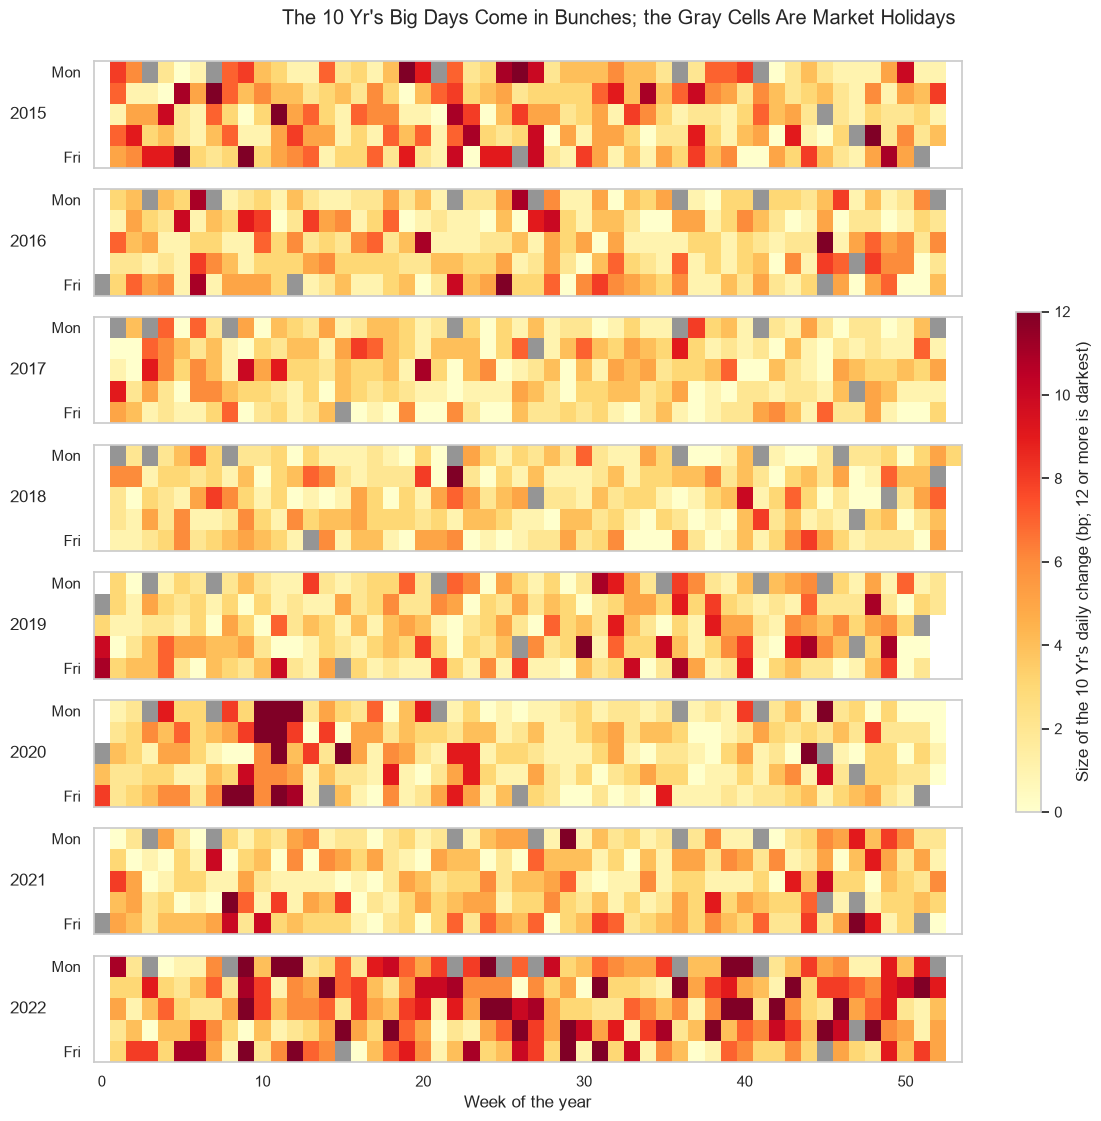

In [12]:
# one strip per year: weekdays down, weeks across, holidays gray, each day coloured by the size of its change
fig, axes = plt.subplots(8, 1, figsize=(14, 13), sharex=True)
for ax, year in zip(axes, range(2015, 2023)):
    days = grid[grid["year"] == year]
    holidays = days.pivot(index="weekday", columns="week", values="holiday").reindex(columns=range(54))
    sizes = days.pivot(index="weekday", columns="week", values="size").reindex(columns=range(54))
    ax.imshow(holidays, cmap="Greys", vmin=0, vmax=2, aspect="auto")
    image = ax.imshow(sizes, cmap="YlOrRd", vmin=0, vmax=12, aspect="auto")
    ax.set_yticks([0, 4], ["Mon", "Fri"])
    ax.set_ylabel(year, rotation=0, ha="right", va="center")
    ax.grid(False)
axes[-1].set_xlabel("Week of the year")
fig.colorbar(image, ax=axes, shrink=0.5, label="Size of the 10 Yr's daily change (bp; 12 or more is darkest)")
fig.suptitle("The 10 Yr's Big Days Come in Bunches; the Gray Cells Are Market Holidays", y=0.92)
plt.show()

In [13]:
# holidays and the average size of a day's change, by year, then the ten largest days with their sign
print("Holidays:", grid.groupby("year")["holiday"].sum().astype(int).to_dict())
print("Average size (bp):", changes["10 Yr"].abs().groupby(changes.index.year).mean().round(2).to_dict())
changes["10 Yr"][changes["10 Yr"].abs().nlargest(10).index]

Holidays: {2015: 9, 2016: 11, 2017: 10, 2018: 12, 2019: 11, 2020: 11, 2021: 10, 2022: 11}
Average size (bp): {2015: 4.38, 2016: 3.42, 2017: 2.77, 2018: 2.73, 2019: 3.4, 2020: 3.65, 2021: 3.35, 2022: 6.3}


date
2022-11-10   -30.0000
2020-03-17    29.0000
2022-06-13    28.0000
2022-09-28   -25.0000
2020-03-10    22.0000
2020-03-16   -21.0000
2020-03-09   -20.0000
2020-03-20   -20.0000
2016-11-09    19.0000
2022-09-22    19.0000
Name: 10 Yr, dtype: float64

Each year has 9 to 12 gray holidays.

The colour comes in seasons: an average day moved 6.30 bp in 2022 and 2.73 in 2018.

March 2020 holds 5 of the 10 largest days; the largest are -30 bp on 2022-11-10 and +29 on 2020-03-17.

**Big days bunch together, so a rule's score depends on which dates it is scored on.**

## A Lag Across a Holiday

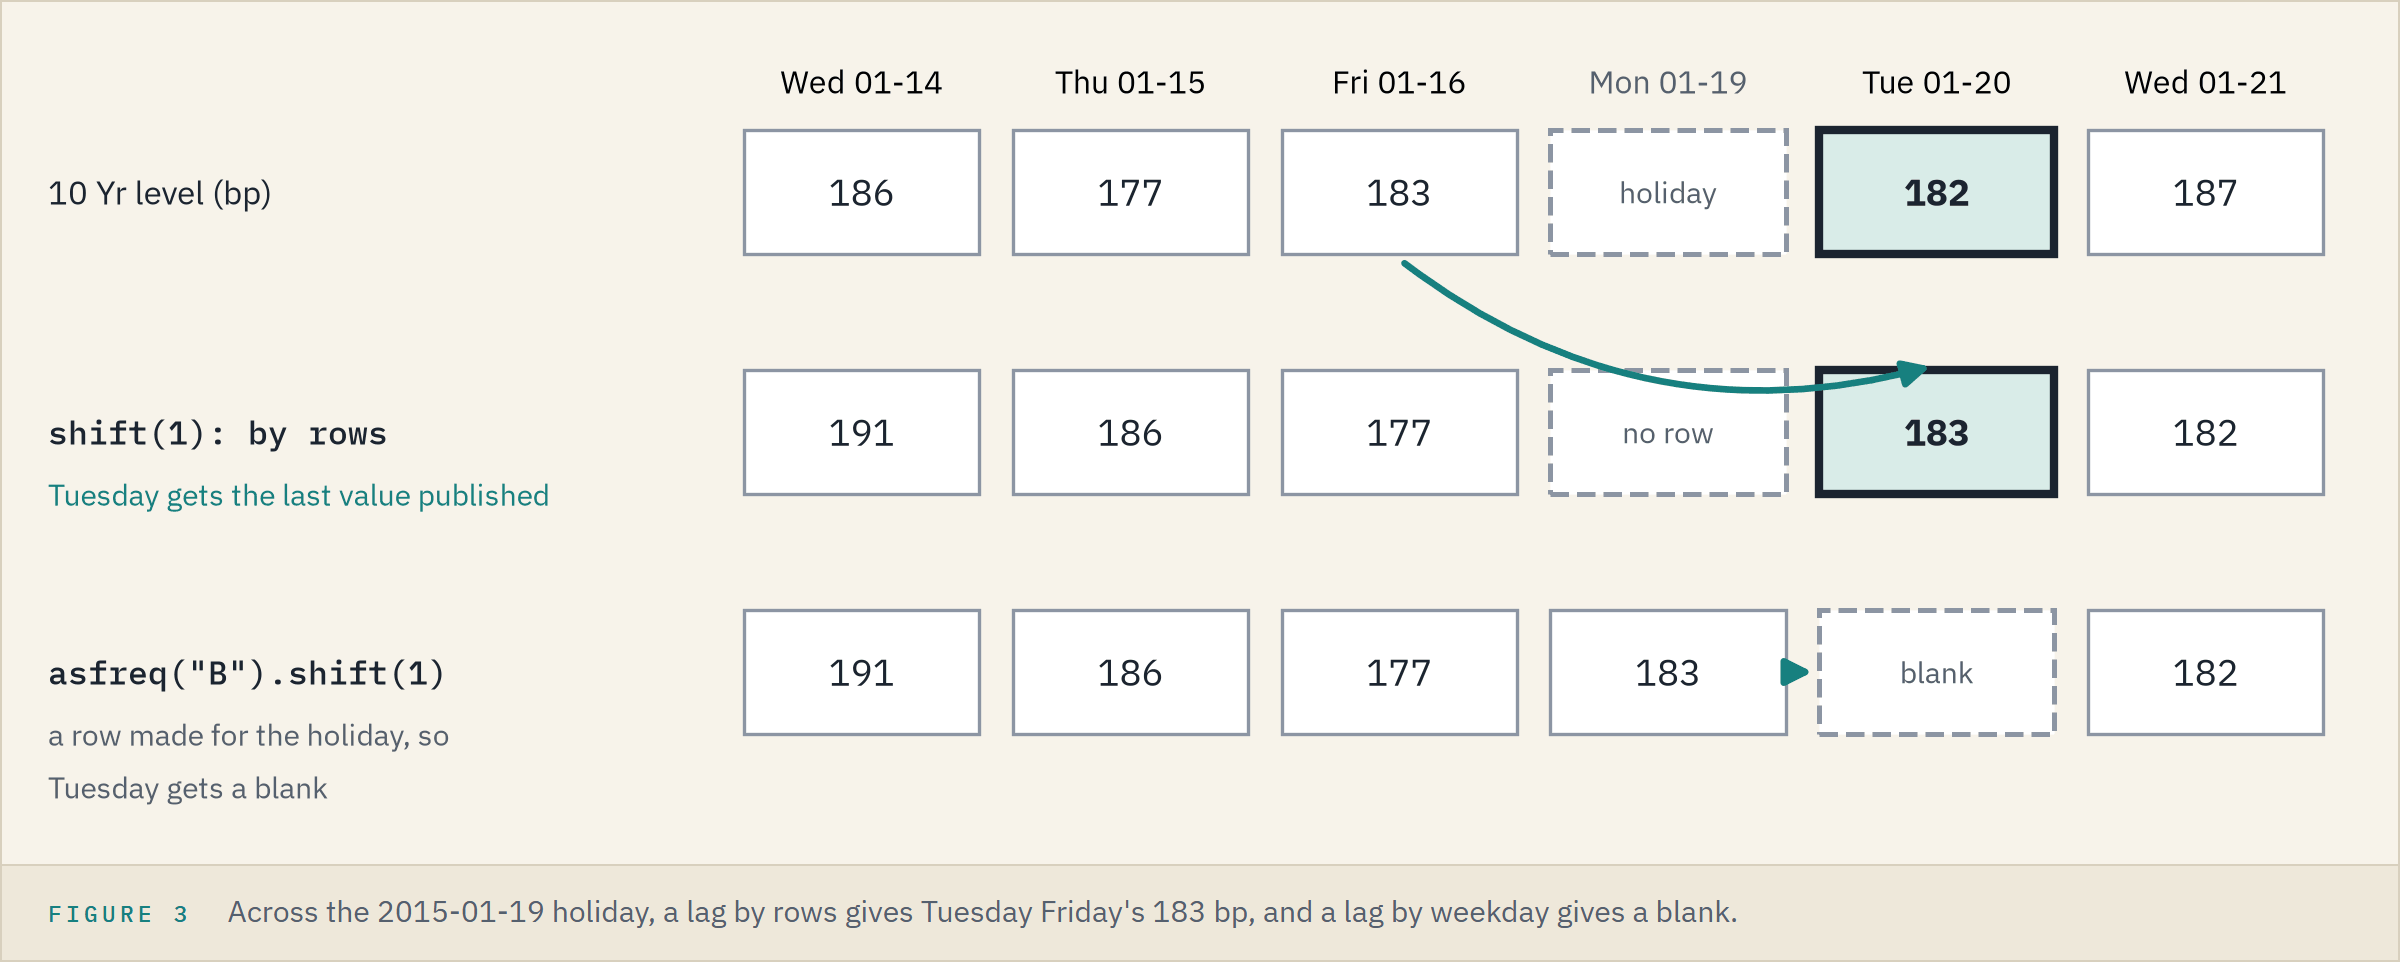

A **lag** is the value k rows before, and `shift(k)` makes it (Course 3).
Lagged by weekday, after Course 3's `asfreq("B")`, the holiday gets a blank row of its own.

In [14]:
# the 10 Yr around Martin Luther King Jr. Day 2015, lagged by rows and lagged by weekday
ten = levels["10 Yr"]
pd.DataFrame({"level": ten, "lag by rows": ten.shift(1), "lag by weekday": ten.asfreq("B").shift(1)}).loc["2015-01-14":"2015-01-21"]

,level,lag by rows,lag by weekday
date,,,
2015-01-14,186.0000,191.0000,191.0000
2015-01-15,177.0000,186.0000,186.0000
2015-01-16,183.0000,177.0000,177.0000
2015-01-19,NaN,NaN,183.0000
2015-01-20,182.0000,183.0000,NaN
2015-01-21,187.0000,182.0000,182.0000


By rows, Tuesday 2015-01-20 gets Friday's 183 bp, the last value anyone could see.

By weekday, Tuesday gets the holiday's blank, and the lag is lost.

**This course lags by rows: a date's last value is the last one published.**

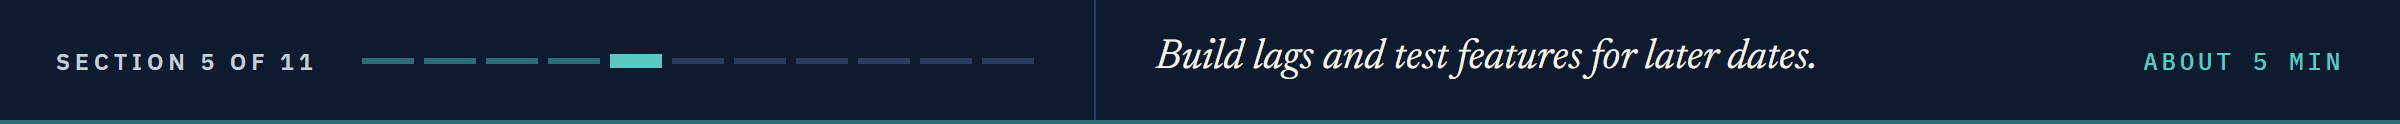

# Data Preparation for Modeling

## Lags and Changes

In [15]:
# the 10 Yr's first six dates: the level, the level one and two rows before, and the change in bp
pd.DataFrame({"level": ten, "lag 1": ten.shift(1), "lag 2": ten.shift(2), "change": ten.diff()}).head(6)

,level,lag 1,lag 2,change
date,,,,
2015-01-02,212.0000,NaN,NaN,NaN
2015-01-05,204.0000,212.0000,NaN,-8.0000
2015-01-06,197.0000,204.0000,212.0000,-7.0000
2015-01-07,196.0000,197.0000,204.0000,-1.0000
2015-01-08,203.0000,196.0000,197.0000,7.0000
2015-01-09,198.0000,203.0000,196.0000,-5.0000


The change is the level less lag 1: 204 less 212 is -8 bp on 2015-01-05.

The first date has no lag and no change, so the development years hold 2,000 changes, from 2015-01-05.

## The Cut Test

Course 3's cut test, as Course 4's Day 11 ran it, stops the data at a cut date, recomputes a feature, and compares.
This course uses a stricter form.
Blank every value from the cut date on, recompute, and compare every value up to and including the cut date.
A feature for scoring a date may use only the dates before it, so not even the cut date's value may move.

In [16]:
# the 10 Yr's changes, and a copy with every change from 2019-12-31 on blanked
TEST_CUT = "2019-12-31"
ten_changes = changes["10 Yr"]
blanked = ten_changes.copy()
blanked.loc[TEST_CUT:] = np.nan

`a.compare(b)` keeps the rows where two Series differ, a blank in both counting as equal.

In [17]:
# recompute a feature on both, then compare every value up to and including the cut date
def cut_test(feature):
    whole, stopped = feature(ten_changes).loc[:TEST_CUT], feature(blanked).loc[:TEST_CUT]
    print("equal:", whole.equals(stopped), "|", len(whole.compare(stopped)), "of", len(whole), "values moved")

In [18]:
# lag 1, and the mean of the 20 changes before each date: both shift first (lambda: a one-line function, Course 1)
cut_test(lambda s: s.shift(1))
cut_test(lambda s: s.shift(1).rolling(20).mean())

equal: True | 0 of 1249 values moved
equal: True | 0 of 1249 values moved


Both features pass: every value up to the cut is the same with or without the later dates.

**Predict 1**

Course 3's trailing mean, `rolling(20).mean()`, has no `shift(1)` in front.

Q. Under the cut test, how many of its 1,249 values up to the cut move? Write down a number.

## Course 3's Trailing Mean

In [19]:
# Course 3's trailing mean of 20 changes, with no shift
cut_test(lambda s: s.rolling(20).mean())

equal: False | 1 of 1249 values moved


In [20]:
# four features on the last six dates up to the cut: 1 where a value moved once the later dates were blanked
features = {"lag 1": lambda s: s.shift(1),
            "mean of the 20 before": lambda s: s.shift(1).rolling(20).mean(),
            "trailing mean of 20": lambda s: s.rolling(20).mean(),
            "whole-history z (Course 4)": lambda s: (s - s.mean()) / s.std()}
moved = pd.DataFrame({name: feature(ten_changes) != feature(blanked) for name, feature in features.items()})
moved = moved.loc[:TEST_CUT].tail(6).T.astype(int)

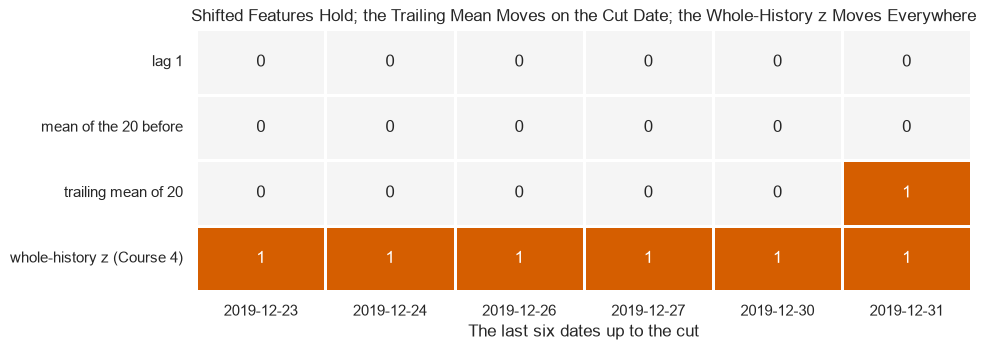

In [21]:
# the tiles: a coloured 1 where the value moved
plt.figure(figsize=(10, 3.4))
sns.heatmap(moved, annot=True, cbar=False, cmap=["whitesmoke", "C3"], linewidths=2,
            xticklabels=moved.columns.strftime("%Y-%m-%d"))
plt.xlabel("The last six dates up to the cut")
plt.title("Shifted Features Hold; the Trailing Mean Moves on the Cut Date; the Whole-History z Moves Everywhere")
plt.show()

### Interpretation of the Cut Test

A trailing window ending on a date holds that date, so the cut date's value moves when the cut date is blanked.

Shifted first, the window stops at the row before, and nothing moves.

Course 4's whole-history z reads every date in the file, so every value moves.

A value may describe its date; an input for scoring that date must stop the row before.

**Every lag and rolling value a model reads in this course passes the cut test first.**

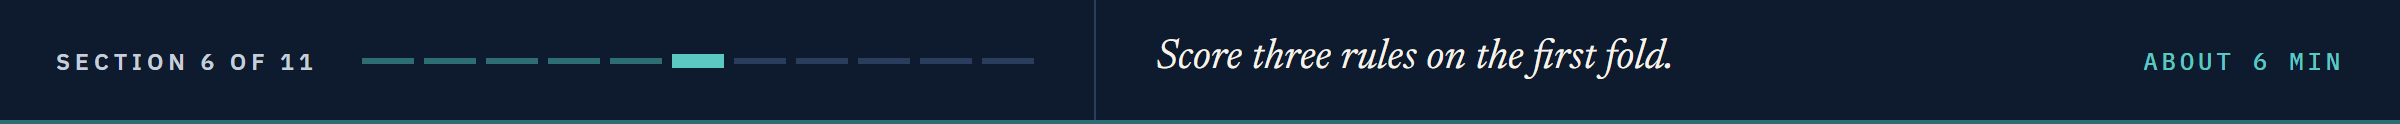

# The Naive Baselines

## Three Rules With No Model

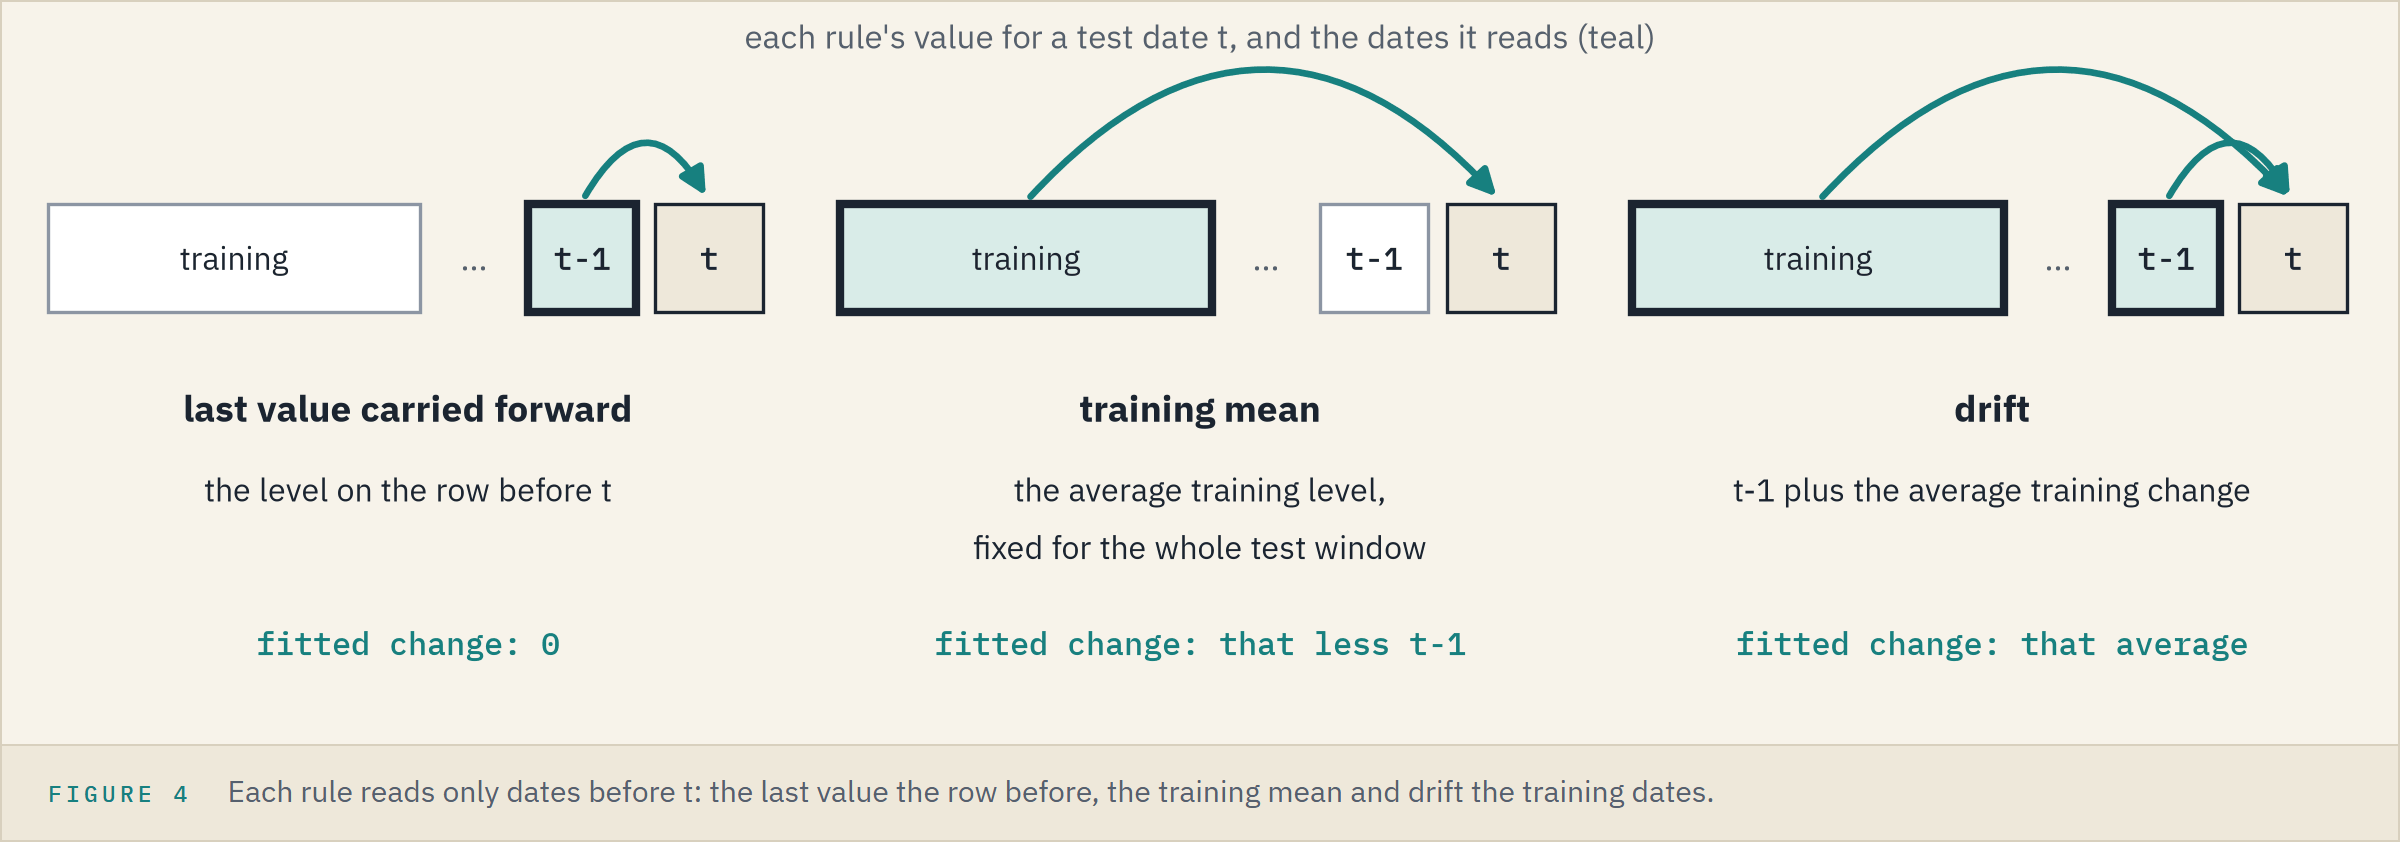

A **naive baseline** is a rule with no model in it, the score anything fitted must beat.

**The last value carried forward**: a date's value is the level on the row before.

**The training mean**: every test date gets the average level of the training dates.

**Drift**: the row before plus the average training change.

A rule's **fitted change** is its value for a date less the level on the row before.
Its miss on the change equals its miss on the level, so every score in this course compares a fitted change with the change that happened, in bp.

## The First Fold of the 10 Yr

The five walk-forward folds of Course 4's Day 11 are set once, here, for every day of this course: `TimeSeriesSplit(n_splits=5, test_size=252)` on the 2,000 changes.
Each fold tests 252 dates, about a trading year, right after its training dates.

In [22]:
# the five folds every day of this course uses: row positions for training, then for testing
folds = list(TimeSeriesSplit(n_splits=5, test_size=252).split(changes))

# the first fold's dates
train, test = changes.index[folds[0][0]], changes.index[folds[0][1]]
print("Training:", len(train), "changes,", train[0].date(), "to", train[-1].date())
print("Test:", len(test), "dates,", test[0].date(), "to", test[-1].date())

Training: 740 changes, 2015-01-05 to 2017-12-14
Test: 252 dates, 2017-12-15 to 2018-12-19


In [23]:
# each rule's fitted change on the 252 test dates, in bp, from the training dates and the row before
actual = changes["10 Yr"][test]
last_value = 0 * actual
drift = last_value + changes["10 Yr"][train].mean()
training_mean = levels["10 Yr"][train].mean() - levels["10 Yr"].shift(1)[test]
print("Training mean level:", round(levels["10 Yr"][train].mean(), 2), "bp | average training change:",
      round(changes["10 Yr"][train].mean(), 3), "bp")

Training mean level: 209.72 bp | average training change: 0.031 bp


In [24]:
# the last value's MAE on the test dates, in bp
last_mae = mean_absolute_error(actual, last_value)
print("Last value:", round(last_mae, 3), "bp")

Last value: 2.69 bp


**Predict 2**

The last value misses fold 1's test dates by 2.69 bp a date, and the training mean is 209.72 bp.

Q. What is the training mean's MAE on the same dates? Write down a number in bp.

In [25]:
# the other two rules on the same dates, and the range of the level on them
training_mean_mae, drift_mae = mean_absolute_error(actual, training_mean), mean_absolute_error(actual, drift)
print("Training mean:", round(training_mean_mae, 3), "bp | Drift:", round(drift_mae, 3), "bp")
print("The 10 Yr on the test dates:", levels["10 Yr"][test].min(), "to", levels["10 Yr"][test].max(), "bp")

Training mean: 79.944 bp | Drift: 2.694 bp
The 10 Yr on the test dates: 235.0 to 324.0 bp


The training mean misses by 79.944 bp a date, thirty times the last value.

Drift misses by 2.694 bp, a hair more than the last value.

**Three rules, each scored on 252 dates after every date it read.**

## The Rules Against the Series

`draw_fold` draws a fold's test dates with each rule's value, and Day 1's inset zoom magnifies the first 15 beside them.

In [26]:
# a fold's test dates: the level, each rule's value for each date, and the first 15 dates zoomed
def draw_fold(series="10 Yr", fold=5):
    train, test = changes.index[folds[fold - 1][0]], changes.index[folds[fold - 1][1]]
    level, before = levels[series][test], levels[series].shift(1)[test]
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.plot(level, color="black", linewidth=2, label="the level")
    ax.plot(before, color="C0", label="last value carried forward")
    ax.plot(before + changes[series][train].mean(), color="C1", linestyle=":", label="drift")
    ax.axhline(levels[series][train].mean(), color="C2", label="training mean")
    zoom = ax.inset_axes([1.04, 0.1, 0.36, 0.8])
    zoom.plot(level[:15], color="black", marker="o")
    zoom.plot(before[:15], color="C0", marker="o")
    zoom.set_xticks([])
    ax.indicate_inset_zoom(zoom)
    ax.set(xlabel="Test date", ylabel=f"{series} (bp)", title=f"{series}, Fold {fold}: Each Rule's Value for Each Test Date")
    zoom.set_title("The first 15 test dates")
    ax.legend(loc="upper left")
    plt.show()

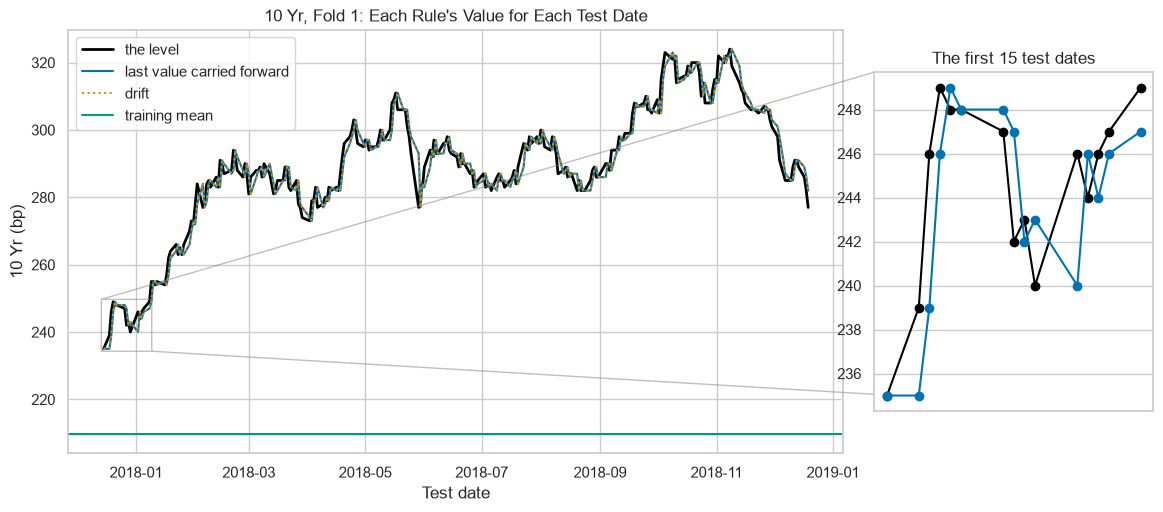

In [27]:
draw_fold("10 Yr", 1)

Fold 1's 10 Yr ran from 235 to 324 bp, above the training mean of 209.7 on every date.

In the zoom each blue dot repeats the black dot before it: the last value is the level one date late.

Drift sits on the last value, 0.031 bp above it.

**The last value misses by the day's change; the training mean misses by how far the level has wandered.**

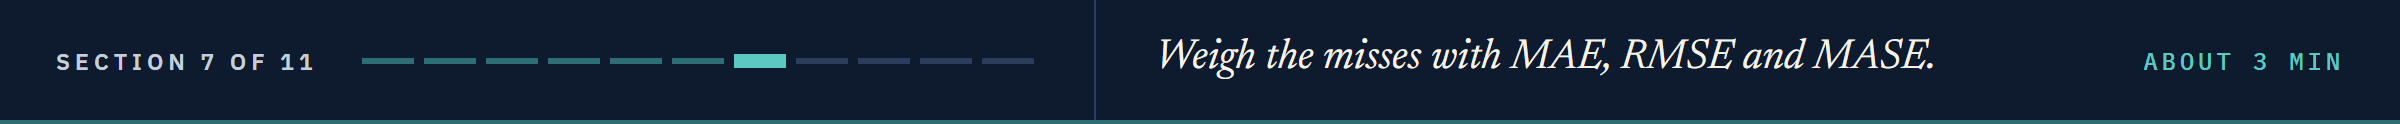

# Scoring a Rule

## MAE and RMSE

Course 4's two scores, in bp:

* **MAE**: the average size of a miss.
* **RMSE**: the root of the average squared miss, so a big miss weighs more.

The last value's fitted change is 0, so its miss on each date is the day's change itself.

In [28]:
# the 1,260 dates the five folds test: from fold 1's first test date to the last development date
scored = changes.index[folds[0][1][0]:]
day_changes = changes["10 Yr"][scored]
mae = mean_absolute_error(day_changes, 0 * day_changes)
rmse = np.sqrt(mean_squared_error(day_changes, 0 * day_changes))
print("Dates:", len(scored), "| MAE:", round(mae, 3), "bp | RMSE:", round(rmse, 3), "bp")

Dates: 1260 | MAE: 3.872 bp | RMSE: 5.294 bp


In [29]:
# the ten largest days' share of the squared misses and of the absolute misses
largest = day_changes.abs().nlargest(10)
print("Share of squared misses:", round((largest ** 2).sum() / (day_changes ** 2).sum() * 100, 1), "percent")
print("Share of absolute misses:", round(largest.sum() / day_changes.abs().sum() * 100, 1), "percent")

Share of squared misses: 15.8 percent
Share of absolute misses: 4.8 percent


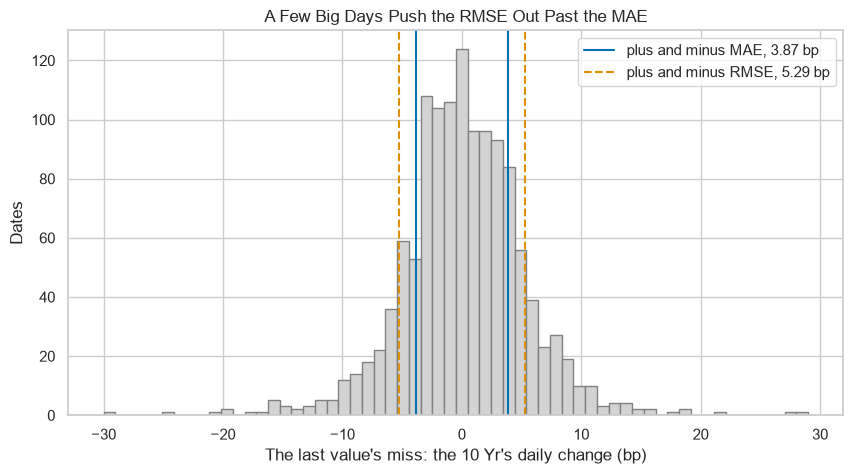

In [30]:
# the last value's misses on the 1,260 dates, with plus and minus MAE and RMSE marked
plt.hist(day_changes, bins=60, color="lightgray", edgecolor="gray")
plt.axvline(mae, color="C0", label=f"plus and minus MAE, {mae:.2f} bp")
plt.axvline(-mae, color="C0")
plt.axvline(rmse, color="C1", linestyle="--", label=f"plus and minus RMSE, {rmse:.2f} bp")
plt.axvline(-rmse, color="C1", linestyle="--")
plt.xlabel("The last value's miss: the 10 Yr's daily change (bp)")
plt.ylabel("Dates")
plt.title("A Few Big Days Push the RMSE Out Past the MAE")
plt.legend()
plt.show()

On 1,260 scored dates the last value misses the 10 Yr by 3.872 bp a date, with an RMSE of 5.294 bp.

The 10 largest days, 0.8 percent of the dates, carry 15.8 percent of the squared misses and 4.8 percent of the absolute.

So RMSE leans on the big days, and MAE reads the typical one.

## MASE: Scoring Against the Last Value

In this course **MASE**, the mean absolute scaled error, divides a rule's MAE by the last value's MAE on the same dates.

In [31]:
# fold 1's MASE for each rule: its MAE over the last value's
print("Training mean MASE:", round(training_mean_mae / last_mae, 4))
print("Drift MASE:", round(drift_mae / last_mae, 4))

Training mean MASE: 29.7136
Drift MASE: 1.0013


### Interpretation of MASE

A MASE of 1 adds nothing to the last value; below 1 a rule misses less, above 1 it misses more.

On fold 1 the training mean misses 29.7 times as far as the last value, and drift 1.001 times.

**Every model in this course ends in a MASE against the last value.**

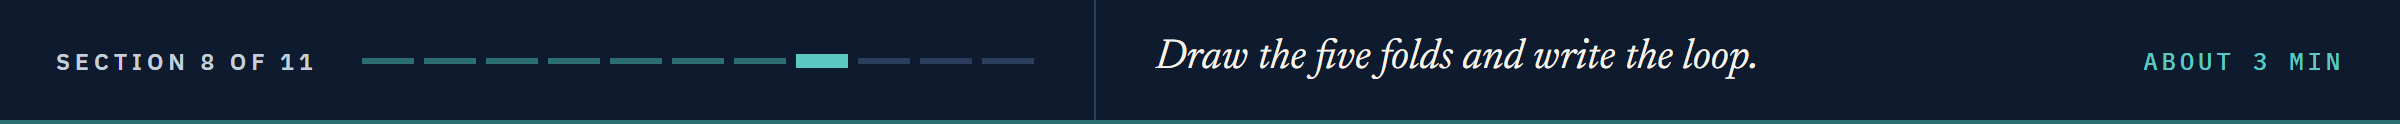

# Walk-Forward Scoring

## Five Folds in Time Order

Each fold trains on every change before its test dates, so the training window grows by a year a fold.

In [32]:
# each fold: its training size and last date, its test dates, and a check that training ends first
for fold, (fit_rows, test_rows) in enumerate(folds, start=1):
    fit_dates, test_dates = changes.index[fit_rows], changes.index[test_rows]
    print("Fold", fold, "| trains on", len(fit_dates), "to", fit_dates[-1].date(), "| tests", test_dates[0].date(),
          "to", test_dates[-1].date(), "| training ends first:", fit_dates[-1] < test_dates[0])

Fold 1 | trains on 740 to 2017-12-14 | tests 2017-12-15 to 2018-12-19 | training ends first: True
Fold 2 | trains on 992 to 2018-12-19 | tests 2018-12-20 to 2019-12-23 | training ends first: True
Fold 3 | trains on 1244 to 2019-12-23 | tests 2019-12-24 to 2020-12-24 | training ends first: True
Fold 4 | trains on 1496 to 2020-12-24 | tests 2020-12-28 to 2021-12-28 | training ends first: True
Fold 5 | trains on 1748 to 2021-12-28 | tests 2021-12-29 to 2022-12-30 | training ends first: True


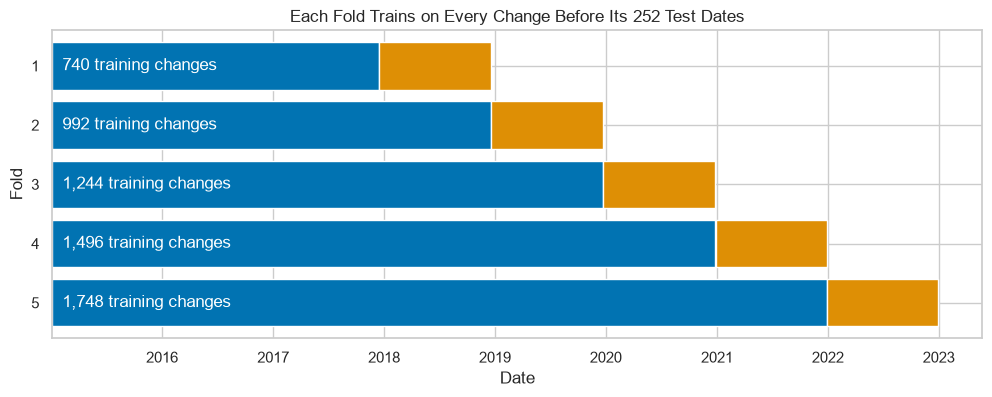

In [33]:
# Course 4's Gantt of the folds: training dates blue, test dates orange
fig, ax = plt.subplots(figsize=(12, 4))
for fold, (fit_rows, test_rows) in enumerate(folds, start=1):
    fit_dates, test_dates = changes.index[fit_rows], changes.index[test_rows]
    ax.barh(fold, fit_dates[-1] - fit_dates[0], left=fit_dates[0], color="C0")
    ax.barh(fold, test_dates[-1] - test_dates[0], left=test_dates[0], color="C1")
    ax.text(fit_dates[0], fold, f"  {len(fit_dates):,} training changes", va="center", color="white")
ax.set(yticks=range(1, 6), ylim=(5.6, 0.4), xlabel="Date", ylabel="Fold")
ax.set_title("Each Fold Trains on Every Change Before Its 252 Test Dates")
plt.show()

Every training window starts on 2015-01-05, and fold 1 takes the 740 changes left over.

The five test windows join up: 1,260 dates from 2017-12-15 to 2022-12-30.

## The Loop Written Out

The **walk-forward loop**: for each fold, fit each rule on the training dates, take its fitted change on each test date, and keep the fold's MAE in bp.
Every later day scores its model with the same loop.

In [34]:
# walk forward on the 10 Yr: each rule fitted on a fold's training dates, scored date by date on its test dates
series = "10 Yr"
rows = []
for fold, (fit_rows, test_rows) in enumerate(folds, start=1):
    fit_dates, test_dates = changes.index[fit_rows], changes.index[test_rows]
    actual = changes[series][test_dates]
    last_value = 0 * actual
    drift = last_value + changes[series][fit_dates].mean()
    training_mean = levels[series][fit_dates].mean() - levels[series].shift(1)[test_dates]
    rows.append([fold, mean_absolute_error(actual, last_value), mean_absolute_error(actual, drift),
                 mean_absolute_error(actual, training_mean)])
ten_scores = pd.DataFrame(rows, columns=["fold", "last value", "drift", "training mean"]).set_index("fold")
ten_scores

,last value,drift,training mean
fold,,,
1,2.6905,2.6939,79.9437
2,3.4444,3.4574,39.1000
3,3.6627,3.6634,136.4033
4,3.3056,3.3193,60.5056
5,6.2579,6.2634,103.1915


### Interpretation of the Fold Scores

The last value misses by 2.69, 3.44, 3.66, 3.31 and 6.26 bp: the year scored matters.

Drift misses by more than the last value in all five folds, by 0.014 bp at most.

The training mean misses by 39.1 to 136.4 bp.

**Each rule is fitted once a fold, on the dates before it, and scored date by date.**

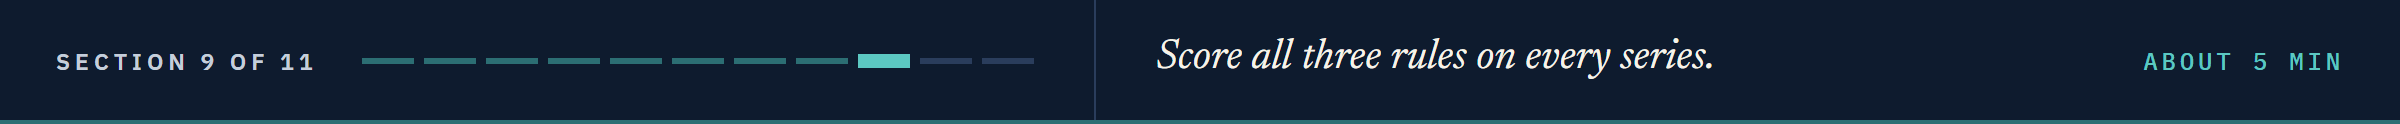

# The Baseline Table for Five Series

**Predict 3**

On the 10 Yr, drift missed by more than the last value in all five folds.

Q. Across five series and five folds, in how many of the 25 does drift have the lower MAE? Write down a number.

## Scoring Every Series

The same loop, inside a loop over the five series.

In [35]:
# the walk-forward loop for every series: one row per series and fold
rows = []
for series in levels.columns:
    for fold, (fit_rows, test_rows) in enumerate(folds, start=1):
        fit_dates, test_dates = changes.index[fit_rows], changes.index[test_rows]
        actual = changes[series][test_dates]
        last_value = 0 * actual
        drift = last_value + changes[series][fit_dates].mean()
        training_mean = levels[series][fit_dates].mean() - levels[series].shift(1)[test_dates]
        rows.append([series, fold, mean_absolute_error(actual, last_value), mean_absolute_error(actual, drift),
                     mean_absolute_error(actual, training_mean)])
fold_scores = pd.DataFrame(rows, columns=["series", "fold", "last value", "drift", "training mean"])
print("Drift lower in", (fold_scores["drift"] < fold_scores["last value"]).sum(), "of", len(fold_scores))
fold_scores[fold_scores["drift"] < fold_scores["last value"]]

Drift lower in 2 of 25


,series,fold,last value,drift,training mean
4,2 Yr,5,6.0675,6.0668,184.5063
14,2s10s,5,3.8413,3.8409,83.3149


In [36]:
# the baseline table: each rule's average fold MAE in bp, and its MASE against the last value
baseline = fold_scores.groupby("series", sort=False)[["last value", "drift", "training mean"]].mean()
baseline["drift MASE"] = baseline["drift"] / baseline["last value"]
baseline["training mean MASE"] = baseline["training mean"] / baseline["last value"]
baseline.style.format("{:.4f}").background_gradient(subset=["training mean MASE"], cmap="Reds")

,last value,drift,training mean,drift MASE,training mean MASE
series,,,,,
2 Yr,3.0024,3.0220,122.9725,1.0065,40.9583
10 Yr,3.8722,3.8795,83.8288,1.0019,21.6488
2s10s,2.5667,2.5791,61.8222,1.0048,24.0866
IG,0.9121,0.9125,8.6708,1.0005,9.5068
HY,3.9370,3.9376,32.4918,1.0002,8.2530


Drift is lower in only 2 of the 25 folds, both in fold 5, by less than a thousandth of a bp.

Its MASE runs from 1.0002 (HY) to 1.0065 (2 Yr).

The training mean's MASE runs from 8.3 (HY) to 41.0 (2 Yr).

## Date by Date

A **cumulative loss difference** adds up, date by date, how much further one rule misses than another: a line that climbs is the first rule losing.

In [37]:
# drift's fitted change on every scored date: the average change of that date's training window
drift_change = pd.DataFrame(index=scored, columns=levels.columns, dtype=float)
for fit_rows, test_rows in folds:
    drift_change.loc[changes.index[test_rows]] = changes.iloc[fit_rows].mean().to_numpy()

# drift's absolute miss less the last value's, then added up date by date, in bp
extra = (changes.loc[scored] - drift_change).abs() - changes.loc[scored].abs()
cumulative = extra.cumsum()
print("Total (bp):", cumulative.iloc[-1].round(2).to_dict())
print("10 Yr: drift closer on", (extra["10 Yr"] < 0).sum(), "dates, further on", (extra["10 Yr"] > 0).sum())

Total (bp): {'2 Yr': 24.68, '10 Yr': 9.17, '2s10s': 15.65, 'IG': 0.55, 'HY': 0.8}
10 Yr: drift closer on 544 dates, further on 716


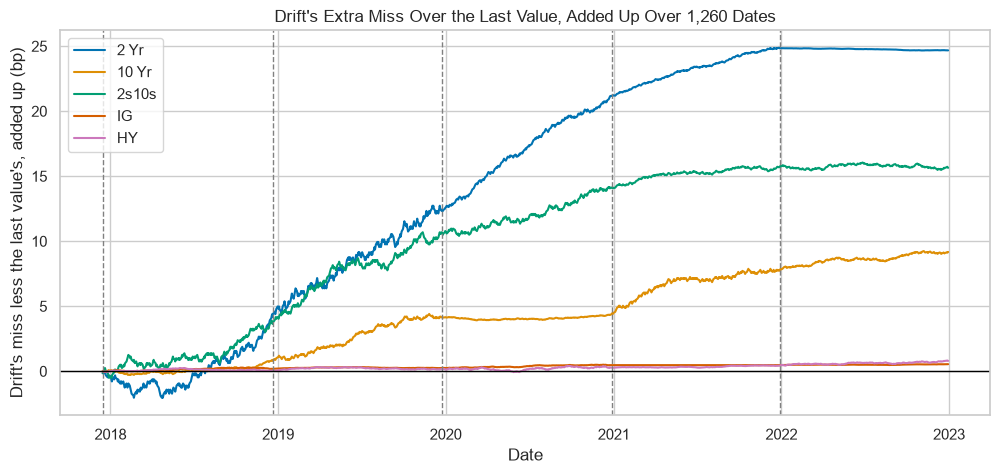

In [38]:
# the running total for each series, with each fold's first test date dashed
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(cumulative, label=cumulative.columns)
for fit_rows, test_rows in folds:
    ax.axvline(changes.index[test_rows[0]], color="gray", linestyle="--", linewidth=1)
ax.axhline(0, color="black", linewidth=1)
ax.set(xlabel="Date", ylabel="Drift's miss less the last value's, added up (bp)")
ax.set_title("Drift's Extra Miss Over the Last Value, Added Up Over 1,260 Dates")
ax.legend()
plt.show()

Over 1,260 dates drift's extra miss on the 10 Yr adds up to 9.17 bp, under a hundredth of a bp a date.

Drift is closer on 544 dates and further on 716: it trades small wins and losses, and ends behind.

## Your Turn: Walk Through Any Fold

Pick a series and a fold, and watch the three rules against the level.

In [39]:
# your turn: pick a series and a fold
interact(draw_fold, series=list(levels.columns), fold=(1, 5));

interactive(children=(Dropdown(description='series', index=1, options=('2 Yr', '10 Yr', '2s10s', 'IG', 'HY'), …

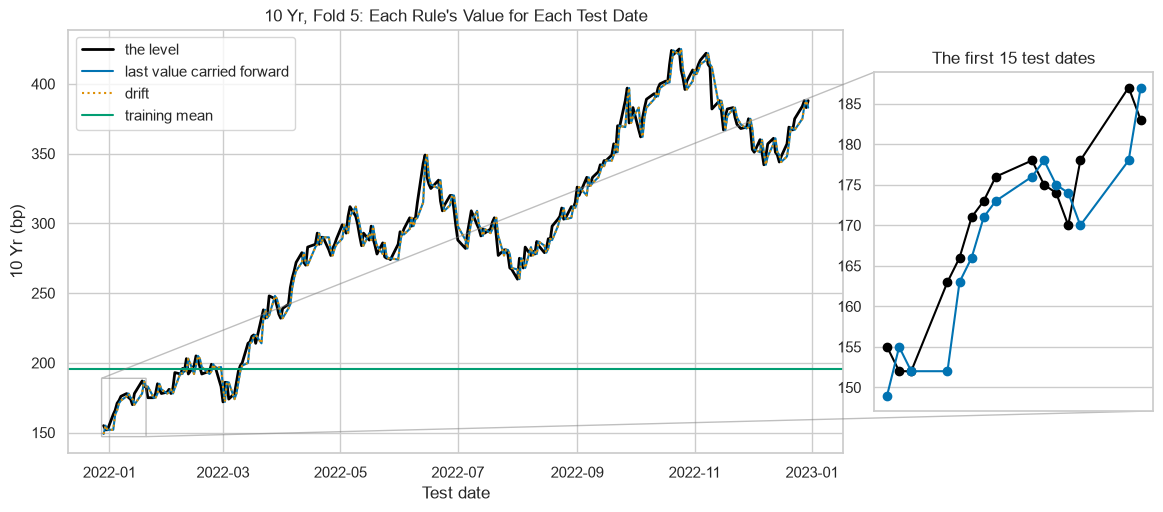

In [40]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_fold("10 Yr", 5)

In 2022 the 10 Yr climbed from below its training mean to far above it, and the last value still trailed it by one date.

**This is the table every later day sits beside.**

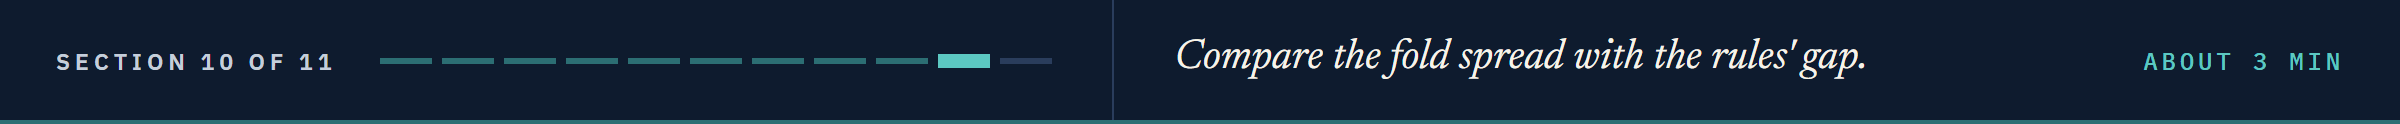

# How Much the Folds Disagree

## The Fold Range Against the Gap Between Rules

In [41]:
# per series: the last value's fold range, and how far drift's average sits from the last value's, in bp
ranges = fold_scores.groupby("series", sort=False)["last value"].agg(["min", "max"])
ranges["fold range"] = ranges["max"] - ranges["min"]
ranges["drift less last value"] = baseline["drift"] - baseline["last value"]
ranges

,min,max,fold range,drift less last value
series,,,,
2 Yr,1.4881,6.0675,4.5794,0.0196
10 Yr,2.6905,6.2579,3.5675,0.0073
2s10s,1.6468,3.8413,2.1944,0.0124
IG,0.7349,1.2087,0.4738,0.0004
HY,3.0635,5.0329,1.9694,0.0006


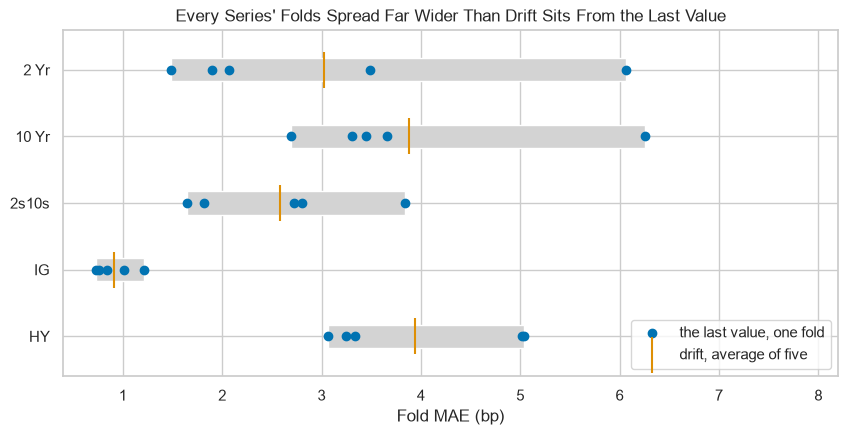

In [42]:
# per series: the five fold MAEs of the last value as dots on their range, drift's average as a tick
fig, ax = plt.subplots(figsize=(10, 4.5))
for row, series in enumerate(levels.columns):
    five = fold_scores.loc[fold_scores["series"] == series, "last value"]
    ax.barh(row, five.max() - five.min(), left=five.min(), height=0.35, color="lightgray")
    ax.scatter(five, [row] * 5, color="C0", zorder=3, label="the last value, one fold" if row == 0 else None)
    ax.scatter(baseline.loc[series, "drift"], row, marker="|", s=700, color="C1", zorder=4,
               label="drift, average of five" if row == 0 else None)
ax.set(yticks=range(5), yticklabels=levels.columns, ylim=(4.6, -0.6), xlim=(0.4, 8.2), xlabel="Fold MAE (bp)")
ax.set_title("Every Series' Folds Spread Far Wider Than Drift Sits From the Last Value")
ax.legend(loc="lower right")
plt.show()

The 10 Yr's folds run from 2.69 to 6.26 bp, a range of 3.57; drift sits 0.007 bp from the last value.

HY's folds spread over 1.97 bp and IG's over 0.47: every range is more than a hundred times the gap between the two rules.

## Shorter Folds

**Predict 4**

Twenty folds of 63 dates test the same 1,260 dates as the five folds of 252.

Q. What is the average of the last value's 20 fold MAEs on the 10 Yr? Write down a number in bp.

In [43]:
# twenty folds of 63 dates, about a quarter each: the last value's MAE on each is the average size of the change
short_folds = TimeSeriesSplit(n_splits=20, test_size=63).split(changes)
short = [changes["10 Yr"].iloc[test_rows].abs().mean() for fit_rows, test_rows in short_folds]
print("Average:", round(np.mean(short), 3), "bp | folds:", round(min(short), 2), "to", round(max(short), 2), "bp")

Average: 3.872 bp | folds: 1.98 to 6.63 bp


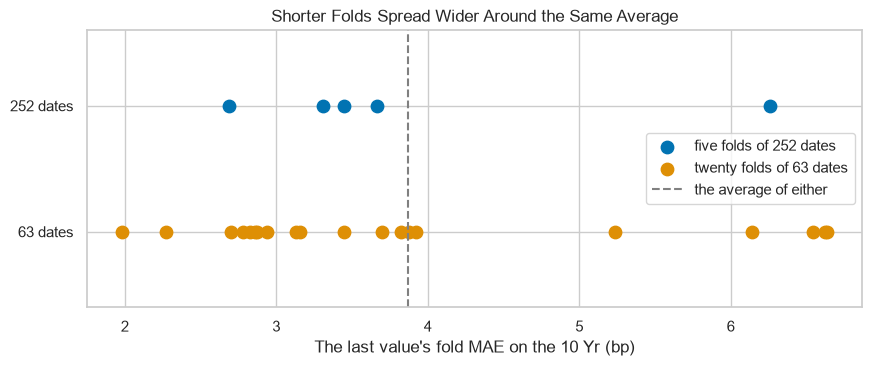

In [44]:
# each fold's MAE as a dot, at 252 dates a fold and at 63, with their average dashed
plt.figure(figsize=(10, 3.6))
plt.scatter(ten_scores["last value"], [1] * 5, s=80, label="five folds of 252 dates")
plt.scatter(short, [0] * 20, s=80, label="twenty folds of 63 dates")
plt.axvline(np.mean(short), color="gray", linestyle="--", label="the average of either")
plt.yticks([0, 1], ["63 dates", "252 dates"])
plt.ylim(-0.6, 1.6)
plt.xlabel("The last value's fold MAE on the 10 Yr (bp)")
plt.title("Shorter Folds Spread Wider Around the Same Average")
plt.legend(loc="center right")
plt.show()

The average is 3.872 bp either way: equal folds on the same dates average to the MAE over all of them.

Shorter folds only spread wider, from 1.98 to 6.63 bp; 252 dates keep a trading year in every fold.

**A model that beats the last value by less than the folds disagree has not beaten it.**

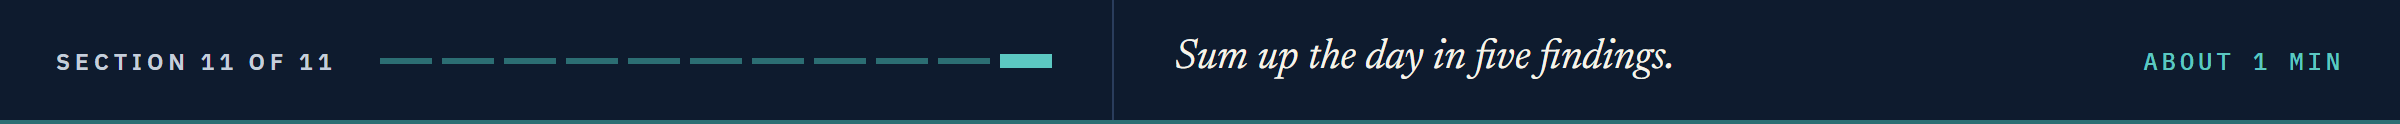

# Insights and Conclusion

The cut and the five folds are fixed for the course: 2,000 development changes, 1,260 scored dates.

The last value misses by the day's change, 3.872 bp on the 10 Yr.

Drift is the last value to within two hundredths of a bp, and lower in 2 of 25 folds.

The training mean is 8 to 41 times worse, because a level wanders far from any earlier average; Day 3 names why.

The folds disagree by far more than the rules do.

**On a daily series, beat the last value by more than the folds disagree, or keep the last value.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Set development and held-out years before looking at the data.
* Build lags and changes by rows, and prove with the cut test that a feature uses only earlier dates.
* Build the last value carried forward, the training mean and drift, and score each with MAE, RMSE and MASE.
* Write the walk-forward loop over `TimeSeriesSplit` folds and build a baseline table for several series.
* Read how far the folds disagree before calling one rule better than another.

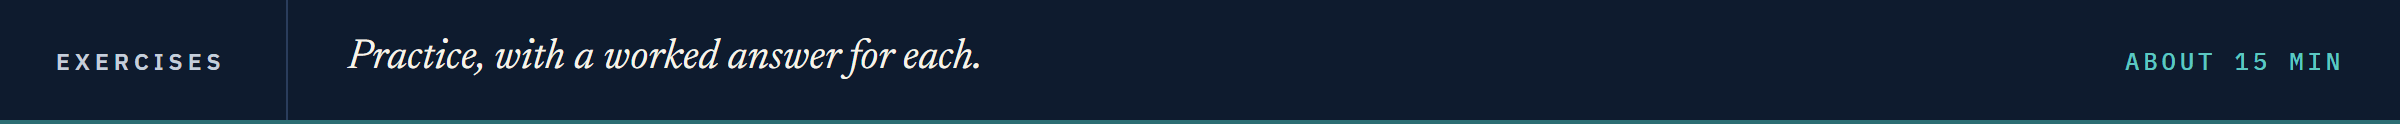

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [45]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Lagging by Weekday**

Q. Lag the 10 Yr by weekday, `levels["10 Yr"].asfreq("B").shift(1)`, and store the number of blank lags in `ex1_blank_lags`.

In [46]:
# your code here
ex1_blank_lags = ...

In [47]:
check("Exercise 1 the blank lags", ex1_blank_lags, 86)

Exercise 1 the blank lags: not attempted yet


### Exercise 2

**Drift on HY in Fold 5**

Q. Store drift's MASE on HY in fold 5, its MAE over the last value's on the same dates, in `ex2_mase`.

In [48]:
# your code here
ex2_mase = ...

In [49]:
check("Exercise 2 drift's MASE on HY in fold 5", ex2_mase, 1.0002977011517067)

Exercise 2 drift's MASE on HY in fold 5: not attempted yet


### Exercise 3

**A Function for the Fold Spread**

Q. Write `fold_spread(fold_maes)`, which returns the highest fold MAE less the lowest, over their average, and store `fold_spread(ten_scores["last value"])` in `ex3_spread`.

In [50]:
# your code here
ex3_spread = ...

In [51]:
check("Exercise 3 the 10 Yr's fold spread", ex3_spread, 0.9212953474072555)

Exercise 3 the 10 Yr's fold spread: not attempted yet


### Exercise 4

**A Fourth Rule**

A fourth rule gives each date the mean of the five levels before it, `levels["10 Yr"].shift(1).rolling(5).mean()`, and its fitted change is that less the level on the row before.

Q. Score it with the walk-forward loop on the 10 Yr, and store its average fold MAE in bp in `ex4_mae`.

In [52]:
# your code here
ex4_mae = ...

In [53]:
check("Exercise 4 the fourth rule's MAE", ex4_mae, 5.623492063492064)

Exercise 4 the fourth rule's MAE: not attempted yet


### Exercise 5: AI check

**The Change That Looked Fine**

You asked an AI assistant for a function that gives each date's change in bp.
This came back, and its average size matches `diff()`.
Test it with the cut test, then find the one bug.
A change may read its own date, so this test blanks only the levels after the cut date.

In [54]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def daily_change(level):
    """The change in bp on each date: the level less the level on the row before."""
    return level.shift(-1) - level

print("Average size:", round(daily_change(levels["10 Yr"]).abs().mean(), 3), "bp | with diff():",
      round(levels["10 Yr"].diff().abs().mean(), 3), "bp")

Average size: 3.748 bp | with diff(): 3.748 bp


In [55]:
# the cut test on the level: blank every level after the cut date, then compare the changes up to and including it
stopped_level = levels["10 Yr"].copy()
stopped_level.loc[stopped_level.index > TEST_CUT] = np.nan
assert daily_change(levels["10 Yr"]).loc[:TEST_CUT].equals(daily_change(stopped_level).loc[:TEST_CUT]), \
    "a change up to the cut moved when later levels were blanked: it reads a later date"

AssertionError: a change up to the cut moved when later levels were blanked: it reads a later date

Q. Fix the one wrong line, and store the fixed function's change on 2020-03-17 in `ex5_change`.

In [56]:
# your code here
ex5_change = ...

In [57]:
check("Exercise 5 the change on 2020-03-17", ex5_change, 29.0)

Exercise 5 the change on 2020-03-17: not attempted yet


## Congratulations!

You set the ground every later day of this course stands on.
You cut the file before looking, built lags by rows, and caught a trailing mean reading a date it should not.
You scored three rules with no model on 1,260 dates, wrote the walk-forward loop, and built the baseline table for five series.
You found the laziest rule the hardest to beat, and the folds disagreeing by far more than the rules.
In Day 3 you find out why the training mean failed so badly, and what that says about every level in this file.

[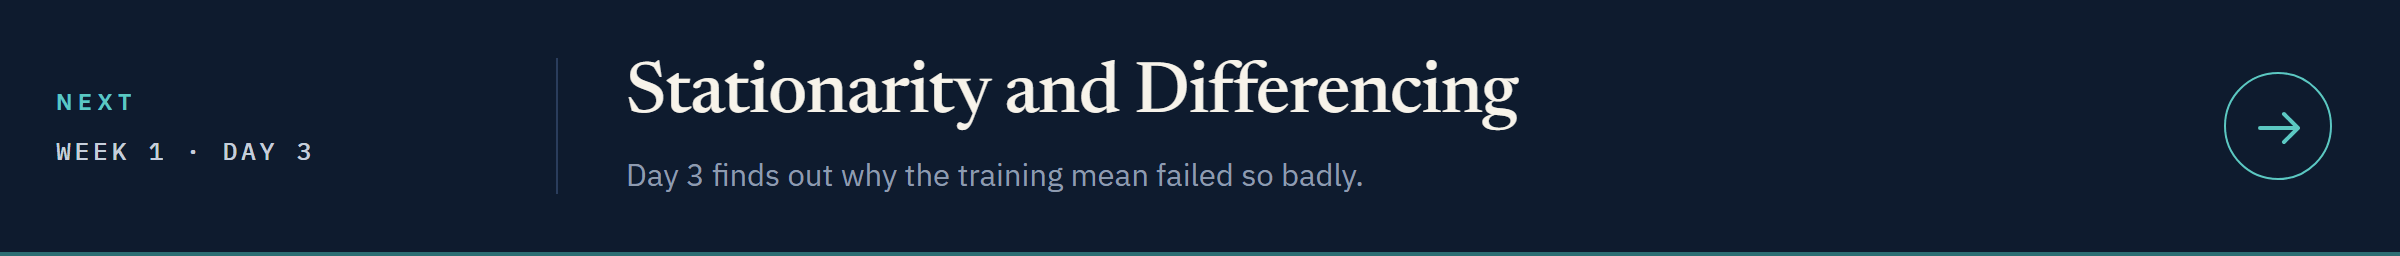](../day3/03_stationarity_and_differencing.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week1/day3/03_stationarity_and_differencing.ipynb)